# Deutsch-Josza Algorithm

In [ ]:
# === BACKEND SETUP (qiskit_backend_config) ===
# -----------------------------------------------
# Common backend helper — works with Qiskit 2.x / qiskit-aer / qiskit-ibm-runtime.
# Provides drop-in replacements for the removed Aer, BasicAer, execute(), and IBMQ.
#
# HOW TO SELECT A BACKEND
# -----------------------
# Simulator (default, runs locally — no credentials needed):
#   BACKEND_NAME = "qasm_simulator"        # shot-based measurements
#   BACKEND_NAME = "statevector_simulator" # full statevector
#   BACKEND_NAME = "unitary_simulator"     # full unitary matrix
#
# Real IBM hardware (requires IBM Quantum account):
#   Set the environment variable:  IBM_QUANTUM_TOKEN=<your_token>
#   Then choose a device, e.g.:
#   BACKEND_NAME = "ibm_brisbane"
#   BACKEND_NAME = "least_busy"  # auto-pick least-busy device
#
import sys, os
sys.path.insert(0, os.path.dirname(os.path.abspath('__file__')))
from qiskit_backend_config import (get_backend, execute, Aer, BasicAer,
                                   IBMQ, least_busy, job_monitor, assemble, combine)

# ── Choose your backend here ──────────────────────────────────────────────
BACKEND_NAME = "qasm_simulator"  # change to a device name for real hardware
# ── (Optional) IBM Quantum token — leave empty to use env var or saved creds
IBM_QUANTUM_TOKEN = os.environ.get("IBM_QUANTUM_TOKEN", "")

# Build the backend object used throughout this notebook
_token_arg = IBM_QUANTUM_TOKEN if IBM_QUANTUM_TOKEN else None
backend = get_backend(BACKEND_NAME, token=_token_arg)
print(f'Backend ready: {backend}')


In [ ]:
#initialization
import matplotlib.pyplot as plt
%matplotlib inline
# initialization
import numpy as np

# importing Qiskit
from qiskit_backend_config import IBMQ, Aer, BasicAer
from qiskit_backend_config import least_busy
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit_backend_config import assemble, execute

# import basic plot tools
from qiskit.visualization import plot_histogram

q_backend = BasicAer.get_backend('qasm_simulator')

## Introduction

The Deutsch-Josza algorithm was the first example of a quantum algorithm which performs better than the best classical algorithm. It showed that there can be advantages in using a quantum computer as a computational tool for a specific problem.

In 1985, David Deutsch found a quantum algorithm to answer in only one evaluation of $f$.<br> 
In 1992, David Deutsch and Richard Josza extended this to the case of $n$ input bits ($2^n$ possible input values)


The algorithm solves the following problem (Deutsch's problem):

Let $f$ be a function such that,  $f : x \in \{0,1\} ⟼ \{0,1\}$, it can be either *constant* or *balanced*. If one wants to know if $f$ is contant or balanced, a classical algorithm needs to calculate the value of $f$ for both possible inputs.

If $U_{f}$ : $f(0) = f(1)  \mapsto $<b> CONSTANT</b> Function and <br>
If $U_{f}$ : $f(0) \ne f(1)\mapsto $<b> BALANCED</b> Function

Explanation: We are given a function $f: \{0,1\} \rightarrow \{0,1\} $ which takes $0$ or $1$ as input and outputs $0$ or $1$. The function itself can be of arbitrary complexity, but the only requirement is that it takes a bit as input and outputs another bit. Given two different inputs $x$ and $y$, check if the function $f(x)$ is equal to $f(y)$.

A classical algorithm solves the problem by evaluating $f(x)$ and $f(y)$ separately and then compare the results. This requires at least two calls to the function $f$. 

<b> Richard Josza's extension (Deutsch-Josza problem)</b>

We are given a hidden Boolean function $f$, which takes a string of bits as input and returns either $0$ or $1$, i.e.,

$ f({x_0,x_1,x_2,...}) \mapsto$ $0$ or $1$, where $x_n$ is $0$ or $1$
 
The property of the given Boolean function is that it is guaranteed to either be balanced or constant. A constant function returns 0 or 1 for all x's as input, while a balanced function returns  0's for exactly half of all inputs and  1's for the other half. Our task is to determine whether the given function is balanced or constant.


The Deutsch-Josza algorithm can solve this problem in only one step!

## The Classical Solution 

Classically, in the best case, two queries to the oracle can determine if the hidden Boolean function,  $f(x)$ , is balanced: e.g. 
if we get both  $f(0,0,0,...)\mapsto$ $0$   and  $f(1,0,0,...)\mapsto$ $1$,  then we know the function is balanced as we have obtained the two different outputs. 
In the worst case, if we continue to see the same output for each input we try, 
we will have to check exactly half of all possible inputs plus one in order to be certain that $f(x)$ is constant. 
Since the total number of possible inputs is $2n$, this implies that we need $2n− 1 + 1$ trial inputs to be certain that $f(x)$ is constant in the worst case. 
For example, for a  4-bit string, if we checked $8$ out of the $16$  possible combinations, getting all  $0$'s, 
it is still possible that the $9$th input returns a $1$ and $f(x)$ is balanced. 
Probabilistically, this is a very unlikely event. 
In fact, if we get the same result continually in succession, 
we can express the probability that the function is constant as a function of $k$ inputs as: 
$$P_\textrm{constant}(k) = 1 - \frac{1}{2^{k-1}} \qquad \textrm{for } 1 < k \leq 2^{n-1}$$  
Realistically, we could opt to truncate our classical algorithm early, say if we were over x% confident. But if we want to be 100% confident, we would need to check $2^{n-1}+1$ inputs.  

# Quantum Solution 

Using a quantum computer, we can solve this problem with 100% confidence after only one call to the function $f(x)$, provided we have the function $f$ implemented as a quantum oracle that maps the state $\vert x\rangle \vert y\rangle$  to  $\vert x\rangle \vert y \oplus f(x)\rangle$,($\oplus$  is addition modulo 2). Below is the generic circuit for the Deutsch-Jozsa algorithm.  
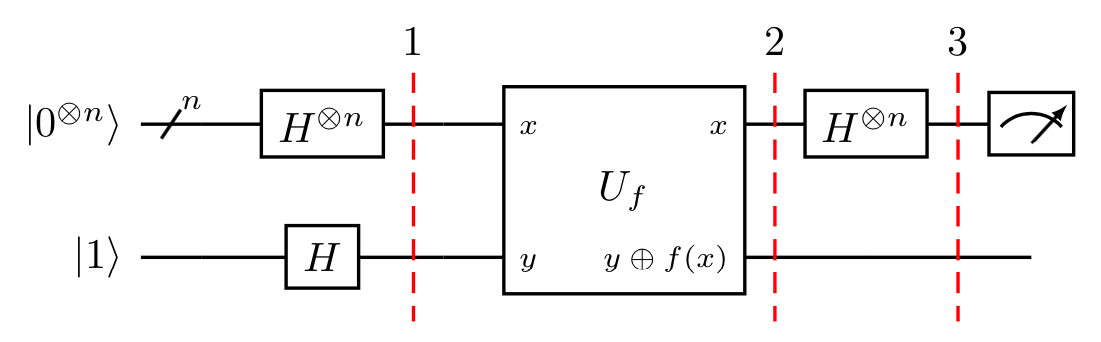

Now, let's go through the steps of the algorithm:  
* Step 1: Prepare two quantum registers. The first is an  n -qubit register initialized to  |0⟩  , and the second is a one-qubit register initialized to  |1⟩  $$\vert \psi_0 \rangle = \vert0\rangle^{\otimes n} \vert 1\rangle$$  
* Step 2: Apply a Hadamard gate to each qubit: 
$$\vert \psi_1 \rangle = \frac{1}{\sqrt{2^{n+1}}}\sum_{x=0}^{2^n-1} \vert x\rangle \left(|0\rangle - |1 \rangle \right)$$
* Step 3: Apply the quantum oracle  |x⟩ | y ⟩   to  |x⟩ | y ⊕ f ( x ) ⟩ $$\begin{aligned}
        \lvert \psi_2 \rangle  
                & = \frac{1}{\sqrt{2^{n+1}}}\sum_{x=0}^{2^n-1} \vert x\rangle (\vert f(x)\rangle - \vert 1 \oplus f(x)\rangle) \\  
                & = \frac{1}{\sqrt{2^{n+1}}}\sum_{x=0}^{2^n-1}(-1)^{f(x)}|x\rangle ( |0\rangle - |1\rangle ) 
        \end{aligned}$$
        since for each  x,$f(x)$  is either  $0$  or  $1$ . 
* Step 4: At this point the second single qubit register may be ignored. Apply a Hadamard gate to each qubit in the first register: 
$$\begin{aligned}
            \lvert \psi_3 \rangle 
                & = \frac{1}{2^n}\sum_{x=0}^{2^n-1}(-1)^{f(x)}
                    \left[ \sum_{y=0}^{2^n-1}(-1)^{x \cdot y} 
                    \vert y \rangle \right] \\
                & = \frac{1}{2^n}\sum_{y=0}^{2^n-1}
                    \left[ \sum_{x=0}^{2^n-1}(-1)^{f(x)}(-1)^{x \cdot y} \right]
                    \vert y \rangle
        \end{aligned}$$
        where  x⋅ y = x $0$ y $0$ ⊕ x $1$ y $1$ ⊕ … ⊕ x n − $1$ y n − $1$   is the sum of the bitwise product. 
* Step 5: Measure the first register. Notice that the probability of measuring  |0⟩ ⊗ n = | $1$ 2 n ∑ 2 n − $1$ x = $0$ ( − $1$ ) f ( x ) | 2  , which evaluates to  $1$  if  $f(x)$  is constant and  $0$  if  $f(x)$  is balanced. 

1.4 Why Does This Work? 

Constant Oracle 

When the oracle is constant, it has no effect (up to a global phase) on the input qubits, and the quantum states before and after querying the oracle are the same. Since the H-gate is its own inverse, in Step 4 we reverse Step 2 to obtain the initial quantum state of  |00 … $0$ ⟩   in the first register.  
$$H^{\otimes n}\begin{bmatrix} 1 \\ 0 \\ 0 \\ \vdots \\ 0 \end{bmatrix} 
= 
\tfrac{1}{\sqrt{2^n}}\begin{bmatrix} 1 \\ 1 \\ 1 \\ \vdots \\ 1 \end{bmatrix}
\quad \xrightarrow{\text{after } U_f} \quad
H^{\otimes n}\tfrac{1}{\sqrt{2^n}}\begin{bmatrix} 1 \\ 1 \\ 1 \\ \vdots \\ 1 \end{bmatrix}
= 
\begin{bmatrix} 1 \\ 0 \\ 0 \\ \vdots \\ 0 \end{bmatrix}
$$
Balanced Oracle 

After step 2, our input register is an equal superposition of all the states in the computational basis. When the oracle is balanced, phase kickback adds a negative phase to exactly half these states:  
$$U_f \tfrac{1}{\sqrt{2^n}}\begin{bmatrix} 1 \\ 1 \\ 1 \\ \vdots \\ 1 \end{bmatrix} 
= 
\tfrac{1}{\sqrt{2^n}}\begin{bmatrix} -1 \\ 1 \\ -1 \\ \vdots \\ 1 \end{bmatrix}
$$
The quantum state after querying the oracle is orthogonal to the quantum state before querying the oracle. Thus, in Step 4, when applying the H-gates, we must end up with a quantum state that is orthogonal to  |00 … $0$ ⟩  . This means we should never measure the all-zero state.  


2. Worked Example 

Let's go through a specific example for a two bit balanced function:  Consider a two-bit function $f(x_0,x_1)=x_0 \oplus x_1$ such that $f(0,0) = 0, f(0,1)=1, f(1,0)=1, f(1,1)=0$.

The corresponding phase oracle of this two-bit oralce is $U_f \lvert x_1, x_0 \rangle = (-1)^{f(x_1, x_0)}\lvert x \rangle$

We will now check if this oracle works as expected by taking a example state $\lvert \psi_0 \rangle = \lvert 0 0 \rangle_{01} \otimes \lvert 1 \rangle_{2}$
* 1. The first register of two qubits is initialized to $|00\rangle$ and the second register qubit to $|1\rangle$ (Note that we are using subscripts 0, $1$,  and 2 to index the qubits. A subscript of "01" indicates the state of the register containing qubits $0$ and $1$ 
$\lvert \psi_0 \rangle = \lvert 0 0 \rangle_{01} \otimes \lvert 1 \rangle_{2}$
* 2. Apply Hadamard on all qubits
$$\lvert \psi_1 \rangle = \frac{1}{2} \left( \lvert 0 0 \rangle + \lvert 0 1 \rangle + \lvert 1 0 \rangle + \lvert 1 1 \rangle \right)_{01} \otimes \frac{1}{\sqrt{2}} \left( \lvert 0 \rangle - \lvert 1 \rangle \right)_{2}$$
* 3. The oracle function can be implemented as $\text{Q}_f = CX_{02}CX_{12}$, 
$$\begin{aligned}
        \lvert \psi_2 \rangle & = \frac{1}{2\sqrt{2}} \left[ \lvert 0 0 \rangle_{01} \otimes \left( \lvert 0 \rangle - \lvert 1 \rangle \right)_{2} - \lvert 0 1 \rangle_{01} \otimes \left( \lvert 0 \rangle - \lvert  1 \rangle \right)_{2} - \lvert 1 0 \rangle_{01} \otimes \left( \lvert 0  \rangle - \lvert 1 \rangle \right)_{2} + \lvert 1 1 \rangle_{01} \otimes \left( \lvert 0 \rangle - \lvert 1 \rangle \right)_{2}  \right] \\
        & = \frac{1}{2} \left( \lvert 0 0 \rangle - \lvert 0 1 \rangle - \lvert 1 0 \rangle + \lvert 1 1 \rangle \right)_{01} \otimes \frac{1}{\sqrt{2}} \left( \lvert 0 \rangle - \lvert 1 \rangle \right)_{2} \\
        & = \frac{1}{\sqrt{2}} \left( \lvert 0 \rangle - \lvert 1 \rangle \right)_{0} \otimes \frac{1}{\sqrt{2}} \left( \lvert 0 \rangle - \lvert 1 \rangle \right)_{1} \otimes \frac{1}{\sqrt{2}} \left( \lvert 0 \rangle - \lvert 1 \rangle \right)_{2}
        \end{aligned}$$
* 4. Simplifying this, we get the following: 
$$\begin{aligned}
        \lvert \psi_2 \rangle & = \frac{1}{2\sqrt{2}} \left[ \lvert 0 0 \rangle_{01} \otimes \left( \lvert 0 \rangle - \lvert 1 \rangle \right)_{2} - \lvert 0 1 \rangle_{01} \otimes \left( \lvert 0 \rangle - \lvert  1 \rangle \right)_{2} - \lvert 1 0 \rangle_{01} \otimes \left( \lvert 0  \rangle - \lvert 1 \rangle \right)_{2} + \lvert 1 1 \rangle_{01} \otimes \left( \lvert 0 \rangle - \lvert 1 \rangle \right)_{2}  \right] \\
        & = \frac{1}{2} \left( \lvert 0 0 \rangle - \lvert 0 1 \rangle - \lvert 1 0 \rangle + \lvert 1 1 \rangle \right)_{01} \otimes \frac{1}{\sqrt{2}} \left( \lvert 0 \rangle - \lvert 1 \rangle \right)_{2} \\
        & = \frac{1}{\sqrt{2}} \left( \lvert 0 \rangle - \lvert 1 \rangle \right)_{0} \otimes \frac{1}{\sqrt{2}} \left( \lvert 0 \rangle - \lvert 1 \rangle \right)_{1} \otimes \frac{1}{\sqrt{2}} \left( \lvert 0 \rangle - \lvert 1 \rangle \right)_{2}
        \end{aligned}$$
* 5. Apply Hadamard on the first register $\lvert \psi_3\rangle = \lvert 1 \rangle_{0} \otimes \lvert 1 \rangle_{1} \otimes \left( \lvert 0 \rangle - \lvert 1 \rangle \right)_{2}$
* 6. Measuring the first two qubits will give the non-zero  11  , indicating a balanced function. 

## Creating Quantum Oracles 

Let's see some different ways we can create a quantum oracle.

For a constant function, it is simple:
  1. if f(x) = 0, then apply the  I  gate to the qubit in register 2.
  2. if f(x) = 1, then apply the  X  gate to the qubit in register 2.

For a balanced function, there are many different circuits we can create. One of the ways we can guarantee our circuit is balanced is by performing a CNOT for each qubit in register 1, with the qubit in register 2 as the target. For example:

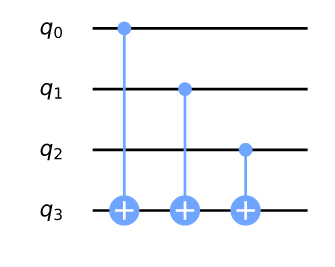

In the image above, the top three qubits form the input register, and the bottom qubit is the output register. We can see which input states give which output in the table below:
<table>
<tr><td>Input states that output 0</td><td>Input States that output 1</td></tr>
<tr>
    <td>000</td><td>001</td>    
</tr>    
<tr>
    <td>011</td><td>100</td>    
</tr>    
<tr>
    <td>101</td><td>010</td>    
</tr>    
<tr>
    <td>110</td><td>111</td>    
</tr>    
</table>    
We can change the results while keeping them balanced by wrapping selected controls in X-gates. For example, see the circuit and its results table below:

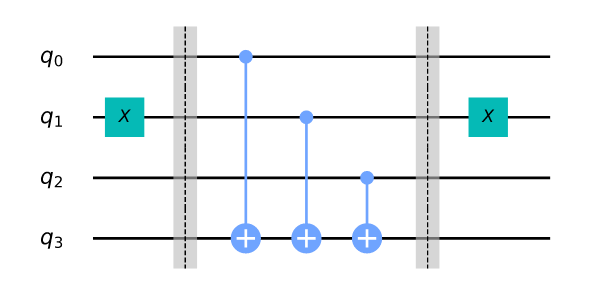


<table>
<tr><td>Input states that output 0</td><td>Input States that output 1</td></tr>
<tr>
    <td>001</td><td>000</td>    
</tr>    
<tr>
    <td>010</td><td>011</td>    
</tr>    
<tr>
    <td>100</td><td>101</td>    
</tr>    
<tr>
    <td>111</td><td>110</td>    
</tr>    


## Simple Qiskit Implementation
We now implement the Deutsch-Jozsa algorithm for the example of a three-bit function, with both constant and balanced oracles.

In [ ]:
# set the length of the n-bit input string. 
n = 3

#We will start by creating a constant oracle, 
#in this case the input has no effect on the output so we just randomly set the output qubit to be 0 or 1
const_oracle = QuantumCircuit(n+1)

output = np.random.randint(2)
if output == 1:
    const_oracle.x(n)

const_oracle.draw()

In [ ]:
## A balanced oracle
# We create a balanced oracle by performing CNOTs with each input qubit as a control and the output bit as the target. 
# We can vary the input states that give 0 or 1 by wrapping some of the controls in X-gates. 
#Let's first choose a binary string of length n that dictates which controls to wrap
b_str = "101"
#Now we have this string, we can use it as a key to place our X-gates. 
balanced_oracle = QuantumCircuit(n+1)

In [ ]:
# Place X-gates - For each qubit in the circuit, we place an X-gate if the corresponding digit in b_str is 1, or do nothing if the digit is 0.
for qubit in range(len(b_str)):
    if b_str[qubit] == '1':
        balanced_oracle.x(qubit)
balanced_oracle.draw()

In [ ]:
# Next, we do our controlled-NOT gates, using each input qubit as a control, and the output qubit as a target:
# Use barrier as divider
balanced_oracle.barrier()

# Controlled-NOT gates
for qubit in range(n):
    balanced_oracle.cx(qubit, n)

balanced_oracle.barrier()
balanced_oracle.draw()

In [ ]:
# finish wrapping the controls in X-gates
# Place X-gates
for qubit in range(len(b_str)):
    if b_str[qubit] == '1':
        balanced_oracle.x(qubit)

# Show oracle
balanced_oracle.draw()

In [ ]:
#The Algorithm - Deutsch-Josza
# Step 1: initialize the input qubits in the state |+⟩  and the output qubit in the state  |−⟩
dj_circuit = QuantumCircuit(n+1, n)
# Apply H-gates
for qubit in range(n):
    dj_circuit.h(qubit)

# Put qubit in state |->
dj_circuit.x(n)
dj_circuit.h(n)
dj_circuit.draw()

In [ ]:
# Step 2: We apply the the balanced_oracle we have created above:
dj_circuit = combine(dj_circuit, balanced_oracle)
dj_circuit.draw()

In [ ]:
# Finally, we perform H-gates on the  n -input qubits, and measure our input register

# Repeat H-gates
for qubit in range(n):
    dj_circuit.h(qubit)
dj_circuit.barrier()

# Measure
for i in range(n):
    dj_circuit.measure(i, i)

# Display circuit
dj_circuit.draw()

In [ ]:
# use local simulator
aer_sim = Aer.get_backend('aer_simulator')
qobj = assemble(dj_circuit, aer_sim)
results = aer_sim.run(qobj).result()
answer = results.get_counts()

plot_histogram(answer)

We can see from the results above that we have a 0% chance of measuring 000. This correctly predicts the function is balanced.

## Generalised Circuits 
Following is a generalised function that creates Deutsch-Jozsa oracles and turns them into quantum gates. It takes the case, (either 'balanced' or 'constant', and n, the size of the input register

In [ ]:
def dj_oracle(case, n):
    # We need to make a QuantumCircuit object to return
    # This circuit has n+1 qubits: the size of the input,
    # plus one output qubit
    oracle_qc = QuantumCircuit(n+1)
    
    # First, let's deal with the case in which oracle is balanced
    if case == "balanced":
        # First generate a random number that tells us which CNOTs to
        # wrap in X-gates:
        b = np.random.randint(1,2**n)
        # Next, format 'b' as a binary string of length 'n', padded with zeros:
        b_str = format(b, '0'+str(n)+'b')
        # Next, we place the first X-gates. Each digit in our binary string 
        # corresponds to a qubit, if the digit is 0, we do nothing, if it's 1
        # we apply an X-gate to that qubit:
        for qubit in range(len(b_str)):
            if b_str[qubit] == '1':
                oracle_qc.x(qubit)
        # Do the controlled-NOT gates for each qubit, using the output qubit 
        # as the target:
        for qubit in range(n):
            oracle_qc.cx(qubit, n)
        # Next, place the final X-gates
        for qubit in range(len(b_str)):
            if b_str[qubit] == '1':
                oracle_qc.x(qubit)

    # Case in which oracle is constant
    if case == "constant":
        # First decide what the fixed output of the oracle will be
        # (either always 0 or always 1)
        output = np.random.randint(2)
        if output == 1:
            oracle_qc.x(n)
    
    oracle_gate = oracle_qc.to_gate()
    oracle_gate.name = "Oracle" # To show when we display the circuit
    return oracle_gate

Let's also create a function that takes this oracle gate and performs the Deutsch-Jozsa algorithm on it

In [ ]:
def dj_algorithm(oracle, n):
    dj_circuit = QuantumCircuit(n+1, n)
    # Set up the output qubit:
    dj_circuit.x(n)
    dj_circuit.h(n)
    # And set up the input register:
    for qubit in range(n):
        dj_circuit.h(qubit)
    # Let's append the oracle gate to our circuit:
    dj_circuit.append(oracle, range(n+1))
    # Finally, perform the H-gates again and measure:
    for qubit in range(n):
        dj_circuit.h(qubit)
    
    for i in range(n):
        dj_circuit.measure(i, i)
    
    return dj_circuit

Finally, let's use these functions to play around with the algorithm

In [ ]:
n = 4
oracle_gate = dj_oracle('balanced', n)
dj_circuit = dj_algorithm(oracle_gate, n)
dj_circuit.draw()

In [ ]:
# And see the results of running this circuit:
transpiled_dj_circuit = transpile(dj_circuit, aer_sim)
qobj = assemble(transpiled_dj_circuit)
results = aer_sim.run(qobj).result()
answer = results.get_counts()
plot_histogram(answer)

# Experiment with Real Devices 

In [ ]:
#Let us find the least-busy device
IBMQ.load_account()
provider = IBMQ.get_provider(hub='ibm-q')
backend = least_busy(provider.backends(filters=lambda x: x.configuration().n_qubits >= (n+1) and
                                   not x.configuration().simulator and x.status().operational==True))
print("least busy backend: ", backend)


from qiskit_backend_config import job_monitor
transpiled_dj_circuit = transpile(dj_circuit, backend, optimization_level=3)
job = backend.run(transpiled_dj_circuit)
job_monitor(job, interval=2)

In [ ]:
# Get the results of the computation
results = job.result()
answer = results.get_counts()
plot_histogram(answer)

As we can see, the most likely result is 1111. The other results are due to errors in the quantum computation.

# Problems 
Are you able to create a balanced or constant oracle of a different form?

The function dj_problem_oracle (below) returns a Deutsch-Jozsa oracle for n = 4 in the form of a gate. The gate takes 5 qubits as input where the final qubit (q_4) is the output qubit (as with the example oracles above). You can get different oracles by giving dj_problem_oracle different integers between 1 and 5. Use the Deutsch-Jozsa algorithm to decide whether each oracle is balanced or constant (Note: It is highly recommended you try this example using the aer_simulator instead of a real device).

In [ ]:
from qiskit_textbook.problems import dj_problem_oracle
oracle = dj_problem_oracle(1)

## References 
* David Deutsch and Richard Jozsa (1992). "Rapid solutions of problems by quantum computation". Proceedings of the Royal Society of London A. 439: 553–558. doi:10.1098/rspa.1992.0167.
* R. Cleve; A. Ekert; C. Macchiavello; M. Mosca (1998). "Quantum algorithms revisited". Proceedings of the Royal Society of London A. 454: 339–354. doi:10.1098/rspa.1998.0164.

In [ ]:
# import qiskit.tools.jupyter  # qiskit.tools.jupyter was removed in Qiskit 1.0
# %qiskit_version_table  # qiskit Jupyter magics were removed in Qiskit 1.0

In [ ]:
'''
    Deutsch-Jozsa Algorithm

    Consider a function f(x) that takes as input n-bit strings x and returns 0 or 1. Suppose we are
    promised that f(x) is either a constant function that takes the same value c in {0,1} on all
    inputs x, or a balanced function that takes each value 0 and 1 on exactly half of the inputs. 
    The goal is to decide whether f is constant or balanced by making as few function evaluations 
    as possible. Classically, it requires 2^{n-1}+1 function evaluations in the worst case. Using 
    the Deutsch-Jozsa algorithm, the question can be answered with just one function evaluation.
    
    Deutsch's algorithm is the simpler case of Deutsch-Jozsa Algorithm which has a function f(x) 
    which takes 1-bit as input.

    Source: https://github.com/Qiskit/ibmqx-user-guides/blob/master/rst/full-user-guide/004-Quantum_Algorithms/080-Deutsch-Jozsa_Algorithm.rst

'''
qr = QuantumRegister(2)  # Initialize two qubits
cr = ClassicalRegister(2)  # Initialize two bits for record measurements
circuit = QuantumCircuit(qr, cr)

circuit.x(qr[1])  # initialize the ancilla qubit in the |1> state

circuit.barrier()

# First step of quantum algorithms - Prepare the superposition
# For superposition, we apply the Hadamard gate on both qubits
circuit.h(qr[0])
circuit.h(qr[1])

circuit.barrier()

# Oracle function
circuit.cx(qr[0], qr[1])

circuit.barrier()

# Apply Hadamard gates after querying oracle function
circuit.h(qr[0])
circuit.h(qr[1])

circuit.barrier()

# Measure qubit
circuit.measure(qr[0], cr[0])
circuit.draw('mpl')

In [ ]:
# Run our circuit with local simulator
shots = 1024
results = execute(circuit, backend=q_backend, shots=shots).result()
answer = results.get_counts()
print("Simulator result")
for c1c0 in answer:
    print(f'c0 = {c1c0[1]} ({answer[c1c0]} shots)')
# C0 observed as 1 in 1024 shots
# It indicates f(0) != f(1)

In [ ]:
# Run our circuit with real devices
IBMQ.load_account()
backend_lb = least_busy(IBMQ.backends(simulator=False))
backend = backend_lb
shots = 1024
job_exp = execute(circuit, backend=backend, shots=shots)
job_monitor(job_exp, interval=2)
results = job_exp.result()
answer = results.get_counts(circuit)
print("Real Device Result")
for c1c0 in answer:
    print(f'c0 = {c1c0[1]} ({answer[c1c0]} shots)')
# As we can see in results, most of the results for C0 is 1
# It indicates f(0) != f(1)
# The results with C0 = 0 occur due to errors in the quantum computation.

In [ ]:
#For 3-Qubits
qr = QuantumRegister(3)  # Initialize qubits
cr = ClassicalRegister(3)  # Initialize bits for record measurements
circuit = QuantumCircuit(qr, cr)

circuit.x(qr[2])  # initialize the ancilla qubit in the |1> state

circuit.barrier()

# First step of quantum algorithms - Prepare the superposition
# For superposition, we apply the Hadamard gate on all qubits
circuit.h(qr[0])
circuit.h(qr[1])
circuit.h(qr[2])

circuit.barrier()

# Oracle function
circuit.h(qr[0])
circuit.cx(qr[1], qr[0])
circuit.z(qr[2])
circuit.h(qr[0])

circuit.barrier()

# Apply Hadamard gates after querying oracle function
circuit.h(qr[0])
circuit.h(qr[1])
circuit.h(qr[2])

circuit.barrier()

# Measure qubit
circuit.measure(qr[0], cr[0])
circuit.measure(qr[1], cr[1])

circuit.barrier()
circuit.draw('mpl')

In [ ]:
# Run our circuit with local simulator
shots = 1024
results = execute(circuit, backend=q_backend, shots=shots).result()
answer = results.get_counts()
print("Simulator result")
for c2c1c0 in answer:
    print(f"{c2c1c0} is observed in {answer[c2c1c0]} times")
# If we measure |0>^n, then f is constant, other results tell us that f is balanced


In [ ]:
#For n-qubit
n = 3
oracle = "b"  # b for balanced, c for constant

if oracle == "b":
    b = 5
if oracle == "c":
    c = 0  # or 1

qr = QuantumRegister(n+1)  # Initialize qubits
cr = ClassicalRegister(n)  # Initialize bits for record measurements
circuit = QuantumCircuit(qr, cr)

circuit.x(qr[n])  # initialize the ancilla qubit in the |1> state

circuit.barrier()

# First step of quantum algorithms - Prepare the superposition
# For superposition, we apply the Hadamard gate on all qubits
circuit.h(qr)

circuit.barrier()

# Oracle function
if oracle == "c":  # constant, return c
    if c == 1:
        circuit.x(qr[n])
    else:
        circuit.id(qr[n])
else:  # balanced, return inner product of input with b
    for i in range(n):
        if (b & (1 << i)):
            circuit.cx(qr[i], qr[n])

circuit.barrier()

# Apply Hadamard gates after querying oracle function
circuit.h(qr)

circuit.barrier()

# Measure qubits
for i in range(n):
    circuit.measure(qr[i], cr[i])

circuit.barrier()
circuit.draw('mpl')

In [ ]:
# Run our circuit with local simulator
shots = 1024
results = execute(circuit, backend=q_backend, shots=shots).result()
answer = results.get_counts()
print("Simulator result")
print(answer)
# If we measure |0>^n, then f is constant, other results tell us that f is balanced


## The Real Way of Using the Algorithm

In [ ]:
#Aqua's TruthTableOracle and DeutschJozsa were removed with Qiskit Aqua;
#these two small functions do the same job with plain circuits.
from qiskit.circuit.library import DiagonalGate

def truth_table_oracle(bitstr):
    """Phase oracle |x> -> (-1)^f(x)|x>, where f(x) is bit x of the truth table."""
    n = int(np.log2(len(bitstr)))
    oracle = QuantumCircuit(n, name='Oracle')
    oracle.append(DiagonalGate([(-1) ** int(b) for b in bitstr]), range(n))
    return oracle

def deutsch_jozsa(oracle, shots=1024):
    """Run Deutsch-Jozsa: the function is constant iff every shot measures |0...0>."""
    n = oracle.num_qubits
    qc = QuantumCircuit(n, n)
    qc.h(range(n))
    qc.compose(oracle, inplace=True)
    qc.h(range(n))
    qc.measure(range(n), range(n))
    counts = execute(qc, q_backend, shots=shots).result().get_counts()
    return {'result': 'constant' if counts.get('0' * n, 0) == shots else 'balanced', 'counts': counts}

#Now let us create a bit string, based on that we use an Oracle to create a circuit
#We have a bitstring, with which we will create an oracle
bitstr = '11110000'
oracle = truth_table_oracle(bitstr)

#An oracle is nothing but a readymade circuit
oracle.decompose().draw(output='mpl')


In [ ]:
#Now we run the Deutsch-Jozsa algorithm on this oracle
result = deutsch_jozsa(oracle)
print('The truth table {} represents a {} function.'.format(bitstr, result['result']))


Aqua also had a dictionary-driven ("parametric") way to run the same thing; `run_algorithm` was removed together with Aqua:

```python
params = {
    'problem': {'name': 'functionevaluation'},
    'algorithm': {'name': 'DeutschJozsa'},
    'oracle': {'name': 'TruthTableOracle', 'bitmaps': [bitstr]},
    'backend': {'shots': 1024},
}
result_dict = run_algorithm(params, backend=q_backend)
```


In [ ]:
#We may create the bit string this way as well
bitstr = '1' * 32
oracle = truth_table_oracle(bitstr)

result = deutsch_jozsa(oracle)
print('The truth table {} represents a {} function.'.format(bitstr, result['result']))
